In [35]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import MinMaxScaler

Load the dataset, find the congestion_level for the next timestamp of the same sensor and filter for entries where the next timestamp happens in 60 minutes.

In [40]:
# Set the path to the file you'd like to load
file_path = "traffic_flow_sensors.csv"

# Load the latest version
df = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS, "olaflundstrom/nordcauc-urban-mobility-intelligence", file_path)

#df["congestion_level"] = df["congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})

df = df.sort_values(by=['sensor_id', 'timestamp'])

df['future_congestion_level'] = df.groupby('sensor_id')['congestion_level'].shift(-1)
df['next_timestamp'] = df.groupby('sensor_id')['timestamp'].shift(-1)
df['duration_to_next'] = pd.to_datetime(df['next_timestamp']) - pd.to_datetime(df['timestamp'])

df = df[df['duration_to_next'].dt.total_seconds() / 60 == 60]

df = df.drop(columns=['next_timestamp', 'duration_to_next'])

C:\Users\Simon\AppData\Local\Temp\ipykernel_8588\2601581359.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS, "olaflundstrom/nordcauc-urban-mobility-intelligence", file_path)


The following columns were removed from the dataset:
* sensor_id: Would not make the model generic
* city: Would not make the model generic
* country: Would not make the model generic
* district: Would not make the model generic
* timestamp: Information covered by more specific columns (e.g. hour or is_weekend)
* date: Information covered by more specific columns
* latitude: Unlikely to be useful
* longitude: Unlikely to be useful
* ev_count_15min: Unlikely to be useful
* ai_predicted_volume: Not part of our problem
* ai_predicted_congestion: Not part of our problem
* ai_model_version: Not part of our problem
* data_quality_flag: We decided to only use good quality data so the column was removed

In [41]:
df_processed = df[df["data_quality_flag"] == "good"]
df_processed = df_processed.drop(columns=["sensor_id", "city", "country", "district", "timestamp", "date", "latitude", "longitude", "ev_count_15min", "ai_predicted_volume", "ai_predicted_congestion", "ai_model_version", "data_quality_flag"])

numeric_cols = df_processed.select_dtypes(include='number').columns

scaler = MinMaxScaler()
df_processed[numeric_cols] = scaler.fit_transform(df_processed[numeric_cols])

In [7]:
x = df_processed.drop(columns=["future_congestion_level"])
y = df_processed["future_congestion_level"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [62]:
base_line = DummyClassifier(strategy="most_frequent").fit(x_train, y_train)
accuracy_score(y_test, base_line.predict(x_test))

0.47101449275362317

In [32]:
df_processed.info()

<class 'pandas.DataFrame'>
Index: 2070 entries, 165398 to 11130
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hour                     2070 non-null   int64  
 1   day_of_week              2070 non-null   str    
 2   is_weekend               2070 non-null   bool   
 3   is_public_holiday        2070 non-null   bool   
 4   season                   2070 non-null   str    
 5   road_type                2070 non-null   str    
 6   speed_limit_kmh          2070 non-null   int64  
 7   lane_count               2070 non-null   int64  
 8   vehicle_count_15min      2070 non-null   int64  
 9   avg_speed_kmh            2070 non-null   float64
 10  congestion_level         2070 non-null   str    
 11  occupancy_rate           2070 non-null   float64
 12  truck_count_15min        2070 non-null   int64  
 13  temperature_c            2070 non-null   float64
 14  precipitation_mm         2070 non-

<class 'pandas.DataFrame'>
Index: 2070 entries, 165398 to 11130
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hour                     2070 non-null   float64
 1   day_of_week              2070 non-null   str    
 2   is_weekend               2070 non-null   bool   
 3   is_public_holiday        2070 non-null   bool   
 4   season                   2070 non-null   str    
 5   road_type                2070 non-null   str    
 6   speed_limit_kmh          2070 non-null   float64
 7   lane_count               2070 non-null   float64
 8   vehicle_count_15min      2070 non-null   float64
 9   avg_speed_kmh            2070 non-null   float64
 10  congestion_level         2070 non-null   str    
 11  occupancy_rate           2070 non-null   float64
 12  truck_count_15min        2070 non-null   float64
 13  temperature_c            2070 non-null   float64
 14  precipitation_mm         2070 non-

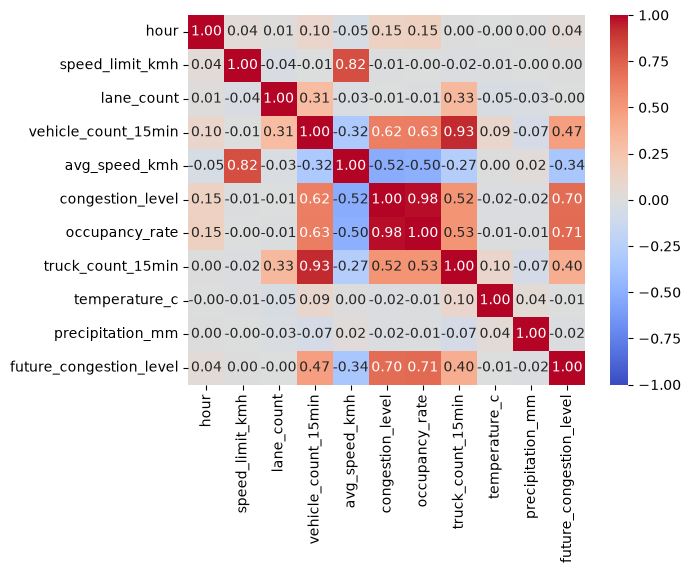

In [48]:
df_clean = df_processed.dropna()

df_clean["future_congestion_level"] = df_clean["future_congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})
df_clean["congestion_level"] = df_clean["congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})

numeric_df = df_clean.select_dtypes(include=['float64','int64'])
print(df_processed.info())
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, vmin=-1, vmax=1, cmap='coolwarm', fmt='.2f')
#plt.savefig('correlation.png')

In [67]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(x_train[["occupancy_rate"]], y_train)
accuracy_score(y_test, tree.predict(x_test[["occupancy_rate"]]))

0.6763285024154589

In [5]:
df["future_congestion_level"].value_counts()

future_congestion_level
free_flow    92425
moderate     38816
light        36835
heavy        31764
Name: count, dtype: int64

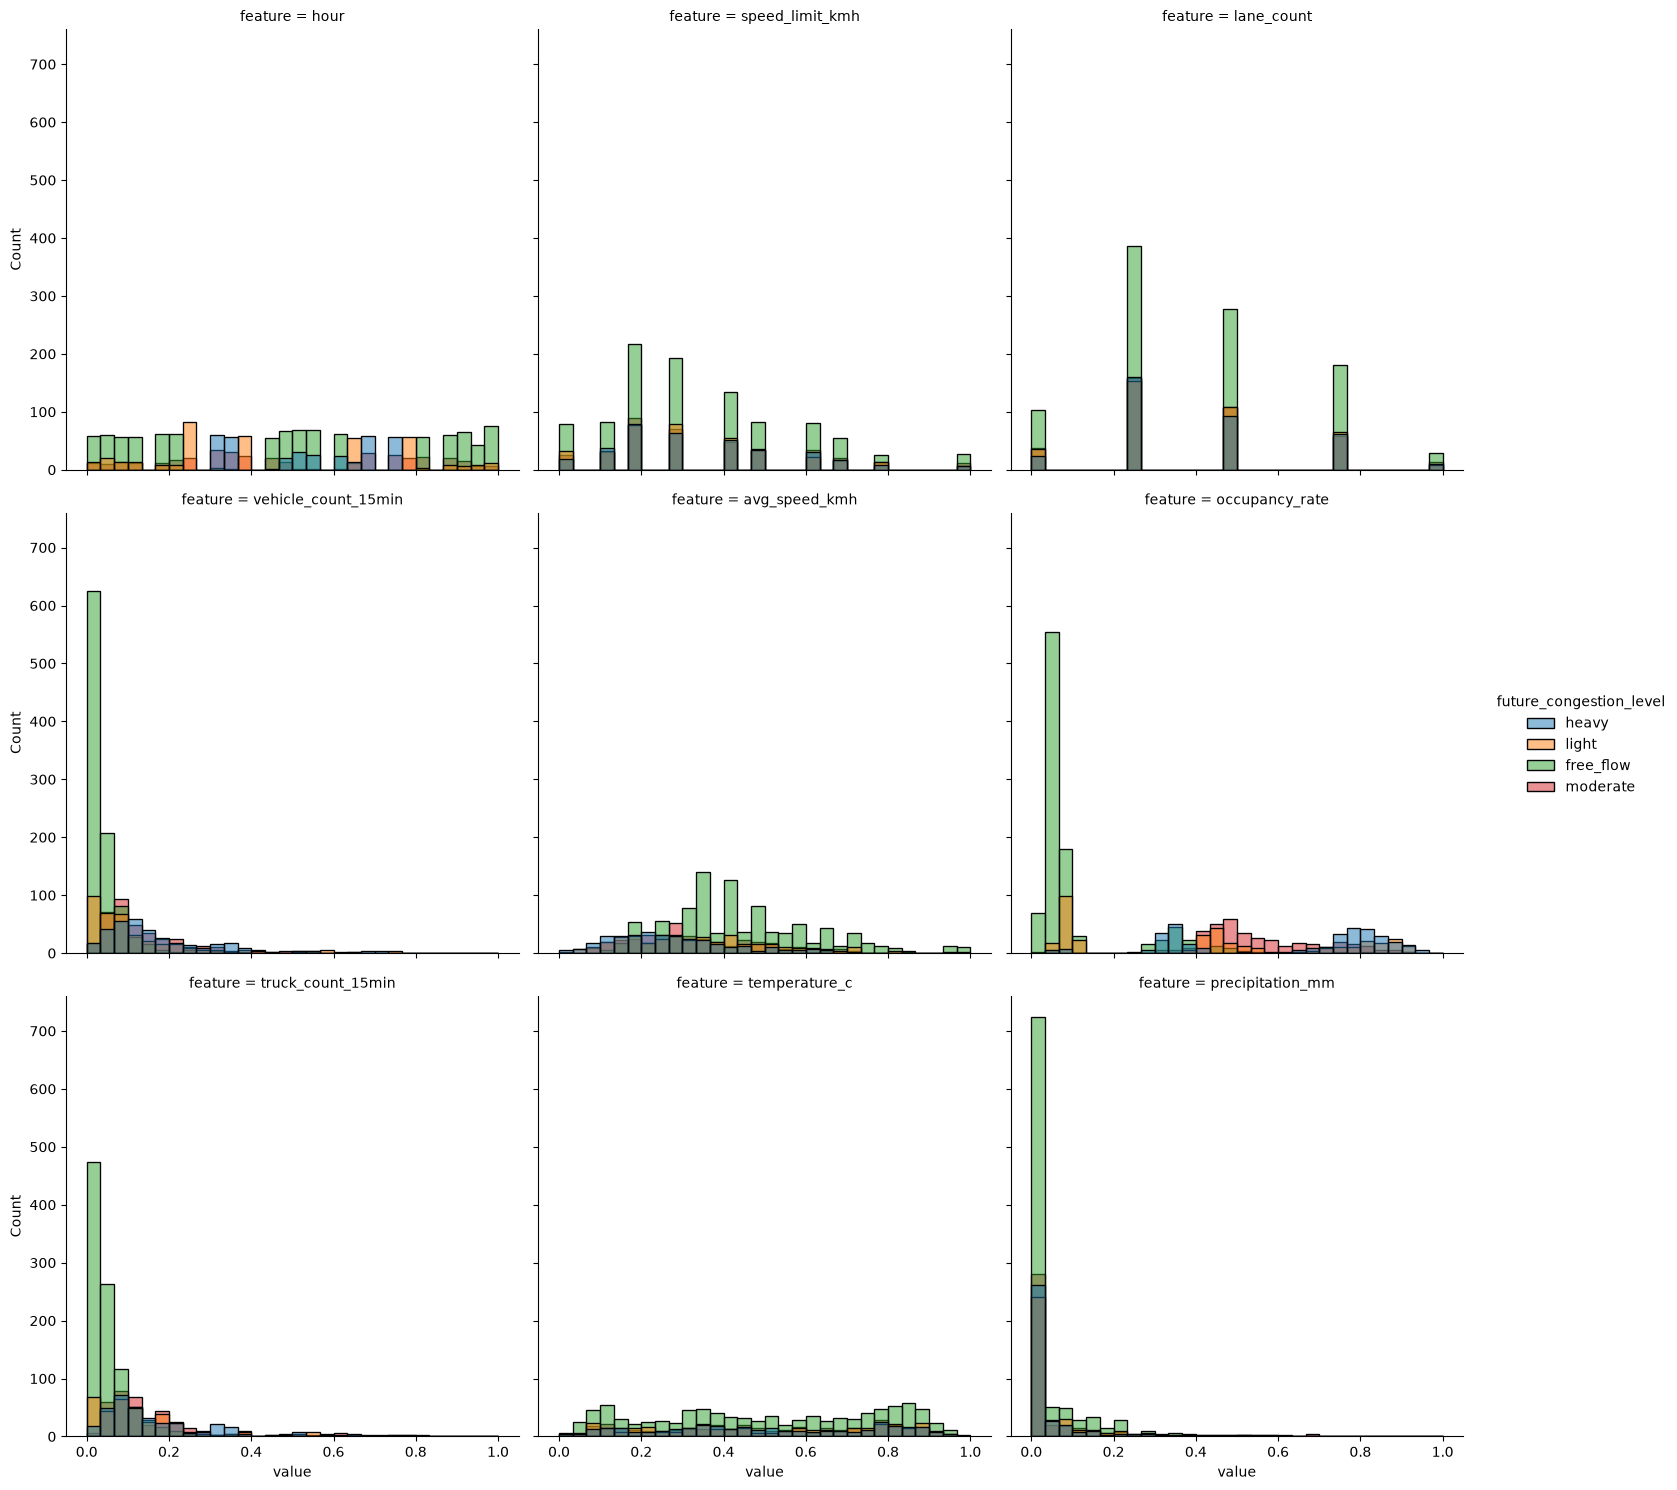

In [49]:
columns_to_drop = df_processed.select_dtypes(include=['string', 'bool']).columns.difference(['future_congestion_level'])
long_df = df_processed.drop(columns=columns_to_drop).melt(id_vars="future_congestion_level", var_name="feature", value_name="value")
sns.displot(data=long_df, x="value", col="feature", hue="future_congestion_level", col_wrap=3)
#plt.savefig('displot.png')

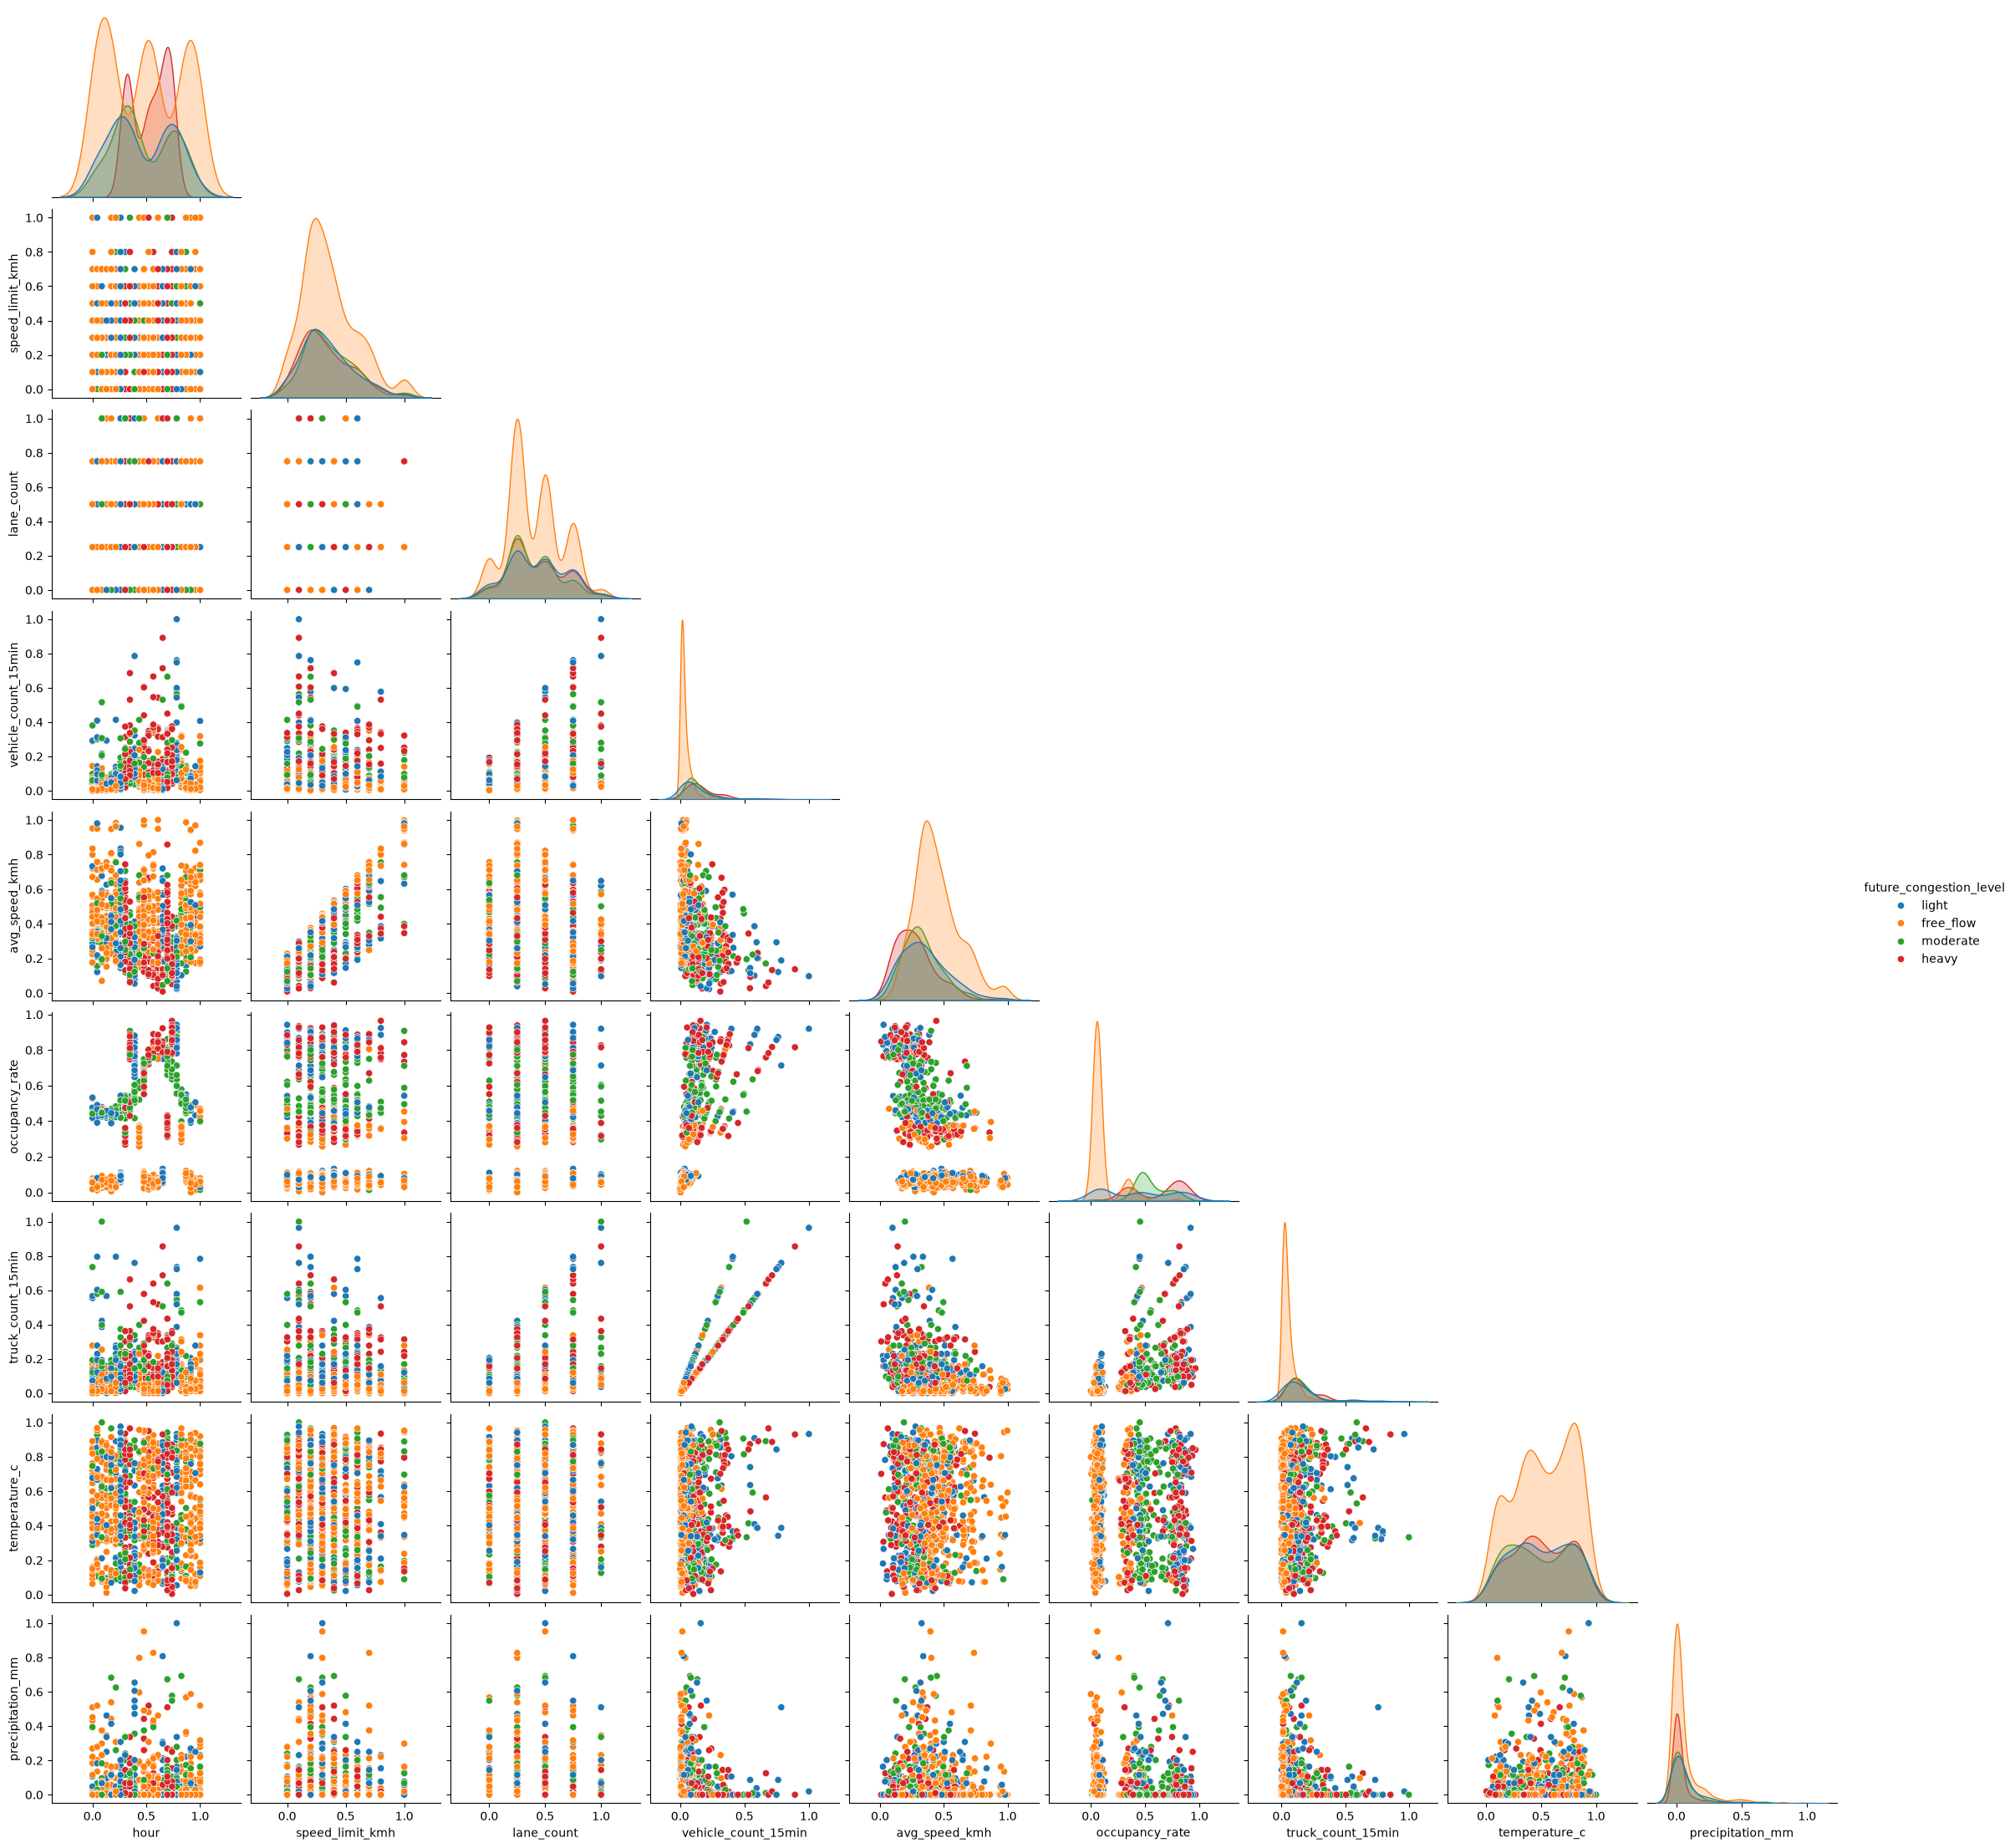

In [50]:
columns_to_drop = df_processed.select_dtypes(include=['string', 'bool']).columns.difference(['future_congestion_level'])
sns.pairplot(df_processed.drop(columns=columns_to_drop).sample(1000, random_state=42), hue="future_congestion_level", corner=True)
#plt.savefig('pairplot.png')